# Atividade 02

Esta é uma versão Python da planilha `MediaMovel.xlsx` para todas as estações e poluentes usados no relatório:

1. Dados: séries horárias das estações `SC0001 (Vila Moema), SC0002 (Capivari) e SC0003 (São Bernardo)`.
2. Representatividade diária, por quadrimestre e anual, com a escolha dos 3 anos.
3. Estatística diária de média móvel de 8 h (O₃ e CO), máxima horária (NO₂) e média diária (MP₁₀, MP₂,₅, SO₂ e PTS).
4. Valor de designação (VD) e enquadramento: fator de excedência (FE) e classe de severidade em cada fase da `CONAMA 506/2024`.
5. Análises complementares de padrões anuais, PTS e sensibilidade do O₃.
6. Comparação com os CSVs de `DATA/dados_tratados` e com a planilha.

# Dados:
- `DataHora` em UTC é convertida para a hora local. Na hora duplicada da saída do horário de verão fica o 1º valor; a hora que não existe na entrada do horário de verão conta como sem dado.
- Hora com valor numérico. Dia válido tem pelo menos 16h válidas. Mês válido pelo menos 2/3 dos dias válidos.
- Ano representativo tem pelo menos 50 % de dias válidos em cada quadrimestre (jan–abr, mai–ago, set–dez).
- Anos do VD: os 3 anos representativos mais recentes, consecutivos ou não.
- Média móvel de 8 h: média da hora atual e das 7 anteriores, válida com pelo menos 6h (3/4). A janela pode atravessar a meia-noite e conta para o dia da sua última hora.
- VD segundo a Tabela 2 do Guia Técnico (BRASIL, 2026b), só com dias válidos. `FE = (VD / PQAr − 1) × 100.`
- Unidades: µg/m³ (CO em ppm). É uma premissa, porque os arquivos brutos não informam a unidade.

## 0. Configuração

In [22]:
import os, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import subprocess

REPO = 'https://github.com/rafa-ds/ENS5173.git'
try:                                    # no Google Colab: baixa o repositório do GitHub com os dados
    import google.colab
    BASE = Path('/content/ENS5173')
    if not BASE.exists():
        subprocess.run(['git', 'clone', '-q', REPO, str(BASE)], check=True)
except ImportError:                     # execução local: pasta do notebook (raiz do repositório)
    BASE = Path.cwd()

DATA = BASE / 'DATA'
REF = DATA / 'dados_tratados'           # resultados usados no relatório (para conferência)
OUT = BASE / 'saida_notebook'           # resultados gerados pelo notebook
OUT.mkdir(exist_ok=True)
assert DATA.exists(), f'Pasta não encontrada: {DATA}. Ajuste a variável BASE.'

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 200)
print('Pasta de dados:', DATA.relative_to(BASE))

Pasta de dados: DATA


In [23]:
NOME = {'SC0001': 'Vila Moema', 'SC0002': 'Capivari', 'SC0003': 'São Bernardo'}
MUNICIPIO = {'SC0001': 'Tubarão', 'SC0002': 'Capivari de Baixo', 'SC0003': 'Tubarão'}
FASES = ['PI-1', 'PI-2', 'PI-3', 'PI-4', 'PF']

# Padrões de curto prazo (CONAMA 506/2024)
PQAR = {
    'MP10': {'PI-1': 120, 'PI-2': 100, 'PI-3': 75, 'PI-4': 50, 'PF': 45},
    'MP25': {'PI-1': 60,  'PI-2': 50,  'PI-3': 37, 'PI-4': 25, 'PF': 15},
    'SO2':  {'PI-1': 125, 'PI-2': 50,  'PI-3': 40, 'PI-4': 40, 'PF': 40},
    'NO2':  {'PI-1': 260, 'PI-2': 240, 'PI-3': 220, 'PI-4': 200, 'PF': 200},
    'O3':   {'PI-1': 140, 'PI-2': 130, 'PI-3': 120, 'PI-4': 100, 'PF': 100},
    'CO':   {'PF': 9},
}
# Padrões anuais e PTS (análise complementar, sem classe de severidade)
PQAR_ANUAL = {
    'MP10': {'PI-1': 40, 'PI-2': 35, 'PI-3': 30, 'PI-4': 20, 'PF': 15},
    'MP25': {'PI-1': 20, 'PI-2': 17, 'PI-3': 15, 'PI-4': 10, 'PF': 5},
    'SO2':  {'PI-1': 40, 'PI-2': 30, 'PI-3': 20, 'PI-4': 20, 'PF': 20},
    'NO2':  {'PI-1': 60, 'PI-2': 50, 'PI-3': 45, 'PI-4': 40, 'PF': 10},
    'PTS':  {'PI-4': 80},
}
PTS24 = {'PI-4': 240}

# Classes de severidade (Guia, Tabela 2): (limite superior exclusivo do FE em %, classe)
SEV = {
    'CO':   [(66.6, 'Moderada'), (np.inf, 'Grave')],
    'NO2':  [(6.25, 'Moderada'), (np.inf, 'Grave')],
    'SO2':  [(42.5, 'Moderada'), (np.inf, 'Grave')],
    'MP10': [(25, 'Moderada'), (np.inf, 'Grave')],
    'MP25': [(25, 'Moderada'), (np.inf, 'Grave')],
    'O3':   [(16, 'Marginal'), (33, 'Moderada'), (50, 'Grave'), (133, 'Severa'), (np.inf, 'Extrema')],
}

## 1. Dados:

Cada arquivo `.csv` tem as colunas `DataHora` (UTC) e `Valor`.

A função `carregar` converte para hora local e coloca a série numa grade horária de 24 h por dia, de 1º de janeiro do primeiro ano a 31 de dezembro do último, como nas colunas A–F da planilha.

In [24]:
def carregar(arquivo):
    df = pd.read_csv(arquivo)
    t = (pd.to_datetime(df['DataHora'], utc=True)
           .dt.tz_convert('America/Sao_Paulo').dt.tz_localize(None))
    s = pd.Series(pd.to_numeric(df['Valor'], errors='coerce').values, index=t)
    s = s.groupby(level=0).first()                 # hora duplicada (horário de verão): 1º valor
    grade = pd.date_range(f'{s.index.min().year}-01-01', f'{s.index.max().year}-12-31 23:00', freq='h')
    return s.reindex(grade)

SERIES = {}
for f in sorted(glob.glob(str(DATA / '**' / 'SC*_filtrado.csv'), recursive=True)):
    est, pol = Path(f).name.split('_')[:2]
    SERIES[(est, pol)] = carregar(f)

resumo = pd.DataFrame([
    dict(estacao=e, nome=NOME[e], poluente=p, inicio=s.first_valid_index(), fim=s.last_valid_index(),
         horas_grade=len(s), horas_validas=int(s.notna().sum()))
    for (e, p), s in SERIES.items()])
resumo

,estacao,nome,poluente,inicio,fim,horas_grade,horas_validas
0,SC0001,Vila Moema,CO,2023-01-01 00:00:00,2024-12-31 15:00:00,17544,8117
1,SC0001,Vila Moema,MP10,2015-01-01 00:00:00,2025-09-25 14:00:00,96432,86845
2,SC0001,Vila Moema,MP25,2015-01-01 00:00:00,2025-09-25 14:00:00,96432,72640
3,SC0001,Vila Moema,NO2,2015-01-01 00:00:00,2025-09-25 14:00:00,96432,87594
4,SC0001,Vila Moema,O3,2015-01-01 09:00:00,2025-09-25 14:00:00,96432,86304
5,SC0001,Vila Moema,PTS,2016-02-19 13:00:00,2025-09-25 14:00:00,96432,80743
6,SC0001,Vila Moema,SO2,2015-01-01 00:00:00,2025-09-25 11:00:00,96432,75879
7,SC0002,Capivari,MP10,2015-01-22 17:00:00,2025-09-25 14:00:00,96432,80823
8,SC0002,Capivari,NO2,2015-01-22 18:00:00,2025-09-25 14:00:00,96432,76015
9,SC0002,Capivari,O3,2016-02-17 17:00:00,2025-09-25 14:00:00,96432,65709


## 2. Representatividade

Corresponde à aba RepresentatividadeAnos da planilha:
- diária: horas válidas por dia (`CONTAGEM`) e dia válido com pelo menos 16h (`REPRESENTATIVIDADE`);
- por quadrimestre: % de dias válidos, representativo com pelo menos 50%;
- anual: ano representativo quando os 3 quadrimestres passam.

In [25]:
def dias_validos(s):
    # True nos dias com >= 16 h válidas
    return s.notna().resample('D').sum() >= 16

linhas, mensal, anos_sel = [], [], []
for (est, pol), s in SERIES.items():
    dv = dias_validos(s)
    hv = s.notna()
    mv = dv.resample('MS').agg(['sum', 'count'])
    mv['ok'] = mv['sum'] >= (2 / 3) * mv['count']
    for ts, r in mv.iterrows():
        mensal.append(dict(estacao=est, poluente=pol, ano=ts.year, mes=ts.month,
                           pct_dias_validos=100 * r['sum'] / r['count']))
    quad = (dv.index.month - 1) // 4 + 1           # 1: jan–abr, 2: mai–ago, 3: set–dez
    for ano in sorted(set(dv.index.year)):
        m = dv.index.year == ano
        rec = dict(estacao=est, poluente=pol, ano=ano,
                   pct_horas_validas=100 * hv[hv.index.year == ano].mean(),
                   pct_dias_validos=100 * dv[m].mean(),
                   meses_validos=int(mv[mv.index.year == ano]['ok'].sum()))
        ok = True
        for q, rot in zip((1, 2, 3), ('Q1_jan_abr', 'Q2_mai_ago', 'Q3_set_dez')):
            mq = m & (quad == q)
            rec[f'pct_dias_validos_{rot}'] = 100 * dv[mq].mean()
            ok &= dv[mq].sum() >= 0.5 * mq.sum()
        rec['ano_representativo'] = bool(ok)
        linhas.append(rec)

REP = pd.DataFrame(linhas)
MENSAL = pd.DataFrame(mensal)
for (est, pol), g in REP.groupby(['estacao', 'poluente']):
    todos = sorted(g.loc[g.ano_representativo, 'ano'])
    anos_sel.append(dict(estacao=est, poluente=pol, anos_selecionados=todos[-3:],
                         n_anos_representativos=len(todos), todos_anos_representativos=todos))
ANOS = pd.DataFrame(anos_sel)
ANOS

,estacao,poluente,anos_selecionados,n_anos_representativos,todos_anos_representativos
0,SC0001,CO,[],0,[]
1,SC0001,MP10,"[2022, 2023, 2024]",10,"[2015, 2016, 2017, 2018, 2019, 2020, 2021, 202..."
2,SC0001,MP25,"[2022, 2023, 2024]",6,"[2018, 2019, 2021, 2022, 2023, 2024]"
3,SC0001,NO2,"[2022, 2023, 2024]",10,"[2015, 2016, 2017, 2018, 2019, 2020, 2021, 202..."
4,SC0001,O3,"[2021, 2023, 2024]",9,"[2015, 2016, 2017, 2018, 2019, 2020, 2021, 202..."
5,SC0001,PTS,"[2022, 2023, 2024]",9,"[2016, 2017, 2018, 2019, 2020, 2021, 2022, 202..."
6,SC0001,SO2,"[2020, 2021, 2024]",7,"[2015, 2016, 2018, 2019, 2020, 2021, 2024]"
7,SC0002,MP10,"[2022, 2023, 2024]",9,"[2015, 2017, 2018, 2019, 2020, 2021, 2022, 202..."
8,SC0002,NO2,"[2019, 2020, 2021]",7,"[2015, 2016, 2017, 2018, 2019, 2020, 2021]"
9,SC0002,O3,"[2021, 2023, 2024]",5,"[2017, 2020, 2021, 2023, 2024]"


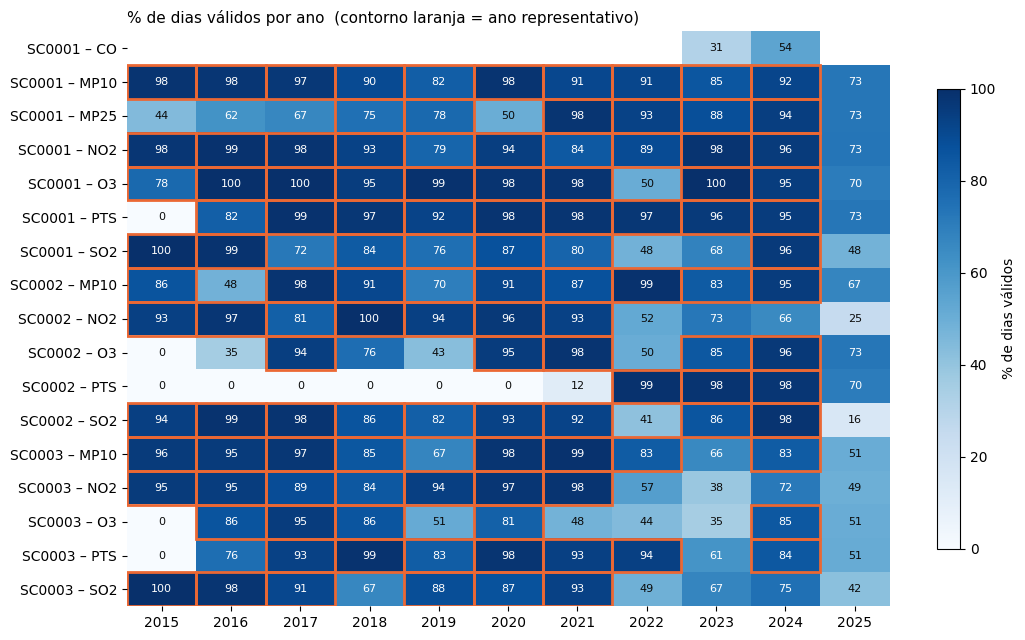

In [26]:
# % de dias válidos por ano (o contorno marca os anos representativos)
tab = REP.pivot_table(index=['estacao', 'poluente'], columns='ano', values='pct_dias_validos')
rep = REP.pivot_table(index=['estacao', 'poluente'], columns='ano', values='ano_representativo', aggfunc='first')

fig, ax = plt.subplots(figsize=(11, 6.5))
im = ax.imshow(tab.values, cmap='Blues', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(tab.shape[1]), tab.columns)
ax.set_yticks(range(tab.shape[0]), [f'{e} – {p}' for e, p in tab.index])
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        v = tab.values[i, j]
        if np.isnan(v):
            continue
        ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=8,
                color='white' if v > 60 else '#0b0b0b')
        if rep.values[i, j] is True:
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec='#eb6834', lw=2))
ax.set_title('% de dias válidos por ano  (contorno laranja = ano representativo)', loc='left', fontsize=11)
for sp in ax.spines.values():
    sp.set_visible(False)
fig.colorbar(im, ax=ax, label='% de dias válidos', shrink=.8)
plt.tight_layout(); plt.show()

## 3. Estatística diária e média móvel de 8 h

Aba `Enquadramento` da planilha. Para O₃ e CO, as colunas da planilha equivalem a:

| Planilha | Aqui |
|---|---|
| `MEDIA_MOVEL` | média de `F` nas 8 h que terminam na hora atual |
| `3/4_VALORES` | pelo menos 6 das 8 h com dado |
| `MESMO_DIA` | janela contínua no tempo, atribuída ao dia da última hora (na série contínua é sempre verdadeiro) |
| `REP_DIA` | dia com pelo menos 16 h válidas |
| `MEDIA_MOVEL_REP` | média móvel que passa nos três critérios |
| `MÁXIMA_MEDIA` | máxima diária de `MEDIA_MOVEL_REP` |

Os demais poluentes usam a máxima horária do dia (NO₂) ou a média diária (MP₁₀, MP₂,₅, SO₂ e PTS), sempre só em dias válidos.

In [27]:
def media_movel_8h(s):
    # tabela hora a hora no formato da aba Enquadramento
    t = pd.DataFrame({'VALOR': s})
    t['N_HORAS_JANELA'] = s.notna().rolling(8, min_periods=1).sum()
    t['MEDIA_MOVEL'] = s.rolling(8, min_periods=1).mean()
    t['3/4_VALORES'] = t['N_HORAS_JANELA'] >= 6
    t['REP_DIA'] = dias_validos(s).reindex(s.index.normalize()).values
    t['MEDIA_MOVEL_REP'] = t['MEDIA_MOVEL'].where(t['3/4_VALORES'] & t['REP_DIA'])
    return t

def estatistica_diaria(s, pol):
    # estatística diária de cada poluente, só nos dias válidos
    if pol in ('O3', 'CO'):
        d = media_movel_8h(s)['MEDIA_MOVEL_REP'].resample('D').max()
    elif pol == 'NO2':
        d = s.resample('D').max()
    else:
        d = s.resample('D').mean()
    return d.where(dias_validos(s))

# exemplo: as primeiras horas de 2018 em SC0003 – O3 (compare com a aba Enquadramento)
media_movel_8h(SERIES[('SC0003', 'O3')]).loc['2018-01-01 06:00':'2018-01-01 18:00'].round(2)

,VALOR,N_HORAS_JANELA,MEDIA_MOVEL,3/4_VALORES,REP_DIA,MEDIA_MOVEL_REP
2018-01-01 06:00:00,NaN,1.0,22.43,False,False,NaN
2018-01-01 07:00:00,NaN,0.0,NaN,False,False,NaN
2018-01-01 08:00:00,NaN,0.0,NaN,False,False,NaN
2018-01-01 09:00:00,4.56,1.0,4.56,False,False,NaN
2018-01-01 10:00:00,9.20,2.0,6.88,False,False,NaN
2018-01-01 11:00:00,16.01,3.0,9.92,False,False,NaN
2018-01-01 12:00:00,17.44,4.0,11.80,False,False,NaN
2018-01-01 13:00:00,19.97,5.0,13.44,False,False,NaN
2018-01-01 14:00:00,NaN,5.0,13.44,False,False,NaN
2018-01-01 15:00:00,NaN,5.0,13.44,False,False,NaN


## 4. Valor de designação (VD) e enquadramento

| Poluente | VD (Guia, Tabela 2) |
|---|---|
| CO | 2ª maior média móvel de 8 h máxima diária no período de 3 anos |
| NO₂ | percentil 98 das máximas horárias diárias |
| SO₂ | percentil 99 das médias diárias |
| MP₁₀ e MP₂,₅ | percentil 98 das médias diárias |
| O₃ | média das 4ª maiores médias móveis de 8 h máximas diárias de cada ano |

O VD é calculado quando existem 3 anos representativos.

In [28]:
def classificar(vd, pol, padroes, severidade=True):
    out = {}
    for fase, p in padroes.items():
        fe = (vd / p - 1) * 100
        if vd <= p:
            cls = 'Atendimento'
        elif not severidade:
            cls = 'Não atendimento'
        else:
            cls = next(c for lim, c in SEV[pol] if fe < lim)
        out[fase] = (cls, fe)
    return out

DIARIO, vd_rows, det_rows = {}, [], []
for _, r in ANOS.iterrows():
    est, pol, anos = r.estacao, r.poluente, r.anos_selecionados
    d = estatistica_diaria(SERIES[(est, pol)], pol)
    d3 = d[d.index.year.isin(anos)].dropna()
    DIARIO[(est, pol)] = d3
    if pol == 'PTS' or len(anos) < 3:
        continue
    q4 = {}
    if pol == 'CO':
        vd, metodo = np.sort(d3.values)[-2], '2ª maior MM8h máx. diária (3 anos)'
    elif pol == 'NO2':
        vd, metodo = np.percentile(d3, 98), 'P98 máx. horárias diárias'
    elif pol == 'SO2':
        vd, metodo = np.percentile(d3, 99), 'P99 médias diárias'
    elif pol in ('MP10', 'MP25'):
        vd, metodo = np.percentile(d3, 98), 'P98 médias diárias'
    elif pol == 'O3':
        q4 = {a: np.sort(d3[d3.index.year == a].values)[-4] for a in anos}
        vd, metodo = np.mean(list(q4.values())), 'média das 4ª maiores MM8h anuais'
    for a in anos:
        da = d3[d3.index.year == a]
        det_rows.append(dict(estacao=est, poluente=pol, ano=a, dias_validos=len(da),
                             max_estatistica_diaria=da.max(), P98_ano=np.percentile(da, 98),
                             P99_ano=np.percentile(da, 99), quarta_maior_MM8h_O3=q4.get(a, np.nan)))
    cl = classificar(vd, pol, PQAR[pol])
    vd_rows.append(dict(estacao=est, municipio=MUNICIPIO[est], poluente=pol,
                        anos_usados=' '.join(map(str, anos)), n_dias_validos=len(d3), metodo=metodo,
                        VD=vd, **{f'{k}_classe': v[0] for k, v in cl.items()},
                        **{f'{k}_FE_pct': v[1] for k, v in cl.items()}))

VD = pd.DataFrame(vd_rows)
DETALHE = pd.DataFrame(det_rows)
VD.round(2)

,estacao,municipio,poluente,anos_usados,n_dias_validos,metodo,VD,PI-1_classe,PI-2_classe,PI-3_classe,PI-4_classe,PF_classe,PI-1_FE_pct,PI-2_FE_pct,PI-3_FE_pct,PI-4_FE_pct,PF_FE_pct
0,SC0001,Tubarão,MP10,2022 2023 2024,979,P98 médias diárias,58.35,Atendimento,Atendimento,Atendimento,Moderada,Grave,-51.37,-41.65,-22.20,16.70,29.67
1,SC0001,Tubarão,MP25,2022 2023 2024,1005,P98 médias diárias,28.77,Atendimento,Atendimento,Atendimento,Moderada,Grave,-52.05,-42.46,-22.24,15.08,91.80
2,SC0001,Tubarão,NO2,2022 2023 2024,1034,P98 máx. horárias diárias,58.09,Atendimento,Atendimento,Atendimento,Atendimento,Atendimento,-77.66,-75.80,-73.60,-70.96,-70.96
3,SC0001,Tubarão,O3,2021 2023 2024,1070,média das 4ª maiores MM8h anuais,113.30,Atendimento,Atendimento,Atendimento,Marginal,Marginal,-19.07,-12.85,-5.58,13.30,13.30
4,SC0001,Tubarão,SO2,2020 2021 2024,962,P99 médias diárias,120.92,Atendimento,Grave,Grave,Grave,Grave,-3.26,141.85,202.31,202.31,202.31
5,SC0002,Capivari de Baixo,MP10,2022 2023 2024,1013,P98 médias diárias,48.79,Atendimento,Atendimento,Atendimento,Atendimento,Moderada,-59.34,-51.21,-34.94,-2.42,8.43
6,SC0002,Capivari de Baixo,NO2,2019 2020 2021,1035,P98 máx. horárias diárias,59.52,Atendimento,Atendimento,Atendimento,Atendimento,Atendimento,-77.11,-75.20,-72.95,-70.24,-70.24
7,SC0002,Capivari de Baixo,O3,2021 2023 2024,1020,média das 4ª maiores MM8h anuais,128.98,Atendimento,Atendimento,Marginal,Moderada,Moderada,-7.87,-0.79,7.48,28.98,28.98
8,SC0002,Capivari de Baixo,SO2,2021 2023 2024,1009,P99 médias diárias,121.16,Atendimento,Grave,Grave,Grave,Grave,-3.07,142.32,202.89,202.89,202.89
9,SC0003,Tubarão,MP10,2021 2022 2024,968,P98 médias diárias,45.26,Atendimento,Atendimento,Atendimento,Atendimento,Moderada,-62.28,-54.74,-39.65,-9.48,0.58


In [29]:
# Quadro-resumo: classe e FE (%) na fase vigente (PI-2) e na fase final (PF)
resumo_vd = VD[['estacao', 'poluente', 'VD', 'PI-2_classe', 'PI-2_FE_pct', 'PF_classe', 'PF_FE_pct']].copy()
resumo_vd.round(1)

,estacao,poluente,VD,PI-2_classe,PI-2_FE_pct,PF_classe,PF_FE_pct
0,SC0001,MP10,58.4,Atendimento,-41.6,Grave,29.7
1,SC0001,MP25,28.8,Atendimento,-42.5,Grave,91.8
2,SC0001,NO2,58.1,Atendimento,-75.8,Atendimento,-71.0
3,SC0001,O3,113.3,Atendimento,-12.8,Marginal,13.3
4,SC0001,SO2,120.9,Grave,141.8,Grave,202.3
5,SC0002,MP10,48.8,Atendimento,-51.2,Moderada,8.4
6,SC0002,NO2,59.5,Atendimento,-75.2,Atendimento,-70.2
7,SC0002,O3,129.0,Atendimento,-0.8,Moderada,29.0
8,SC0002,SO2,121.2,Grave,142.3,Grave,202.9
9,SC0003,MP10,45.3,Atendimento,-54.7,Moderada,0.6


In [30]:
DETALHE.round(2)

,estacao,poluente,ano,dias_validos,max_estatistica_diaria,P98_ano,P99_ano,quarta_maior_MM8h_O3
0,SC0001,MP10,2022,333,68.25,55.50,60.62,NaN
1,SC0001,MP10,2023,311,75.62,49.82,55.34,NaN
2,SC0001,MP10,2024,335,111.25,69.03,84.37,NaN
3,SC0001,MP25,2022,339,36.33,27.77,31.35,NaN
4,SC0001,MP25,2023,321,34.79,21.20,25.98,NaN
5,SC0001,MP25,2024,345,56.62,33.52,38.65,NaN
6,SC0001,NO2,2022,326,100.52,53.35,58.92,NaN
7,SC0001,NO2,2023,358,85.00,57.44,63.50,NaN
8,SC0001,NO2,2024,350,91.03,60.06,70.10,NaN
9,SC0001,O3,2021,358,87.96,78.97,84.76,85.93


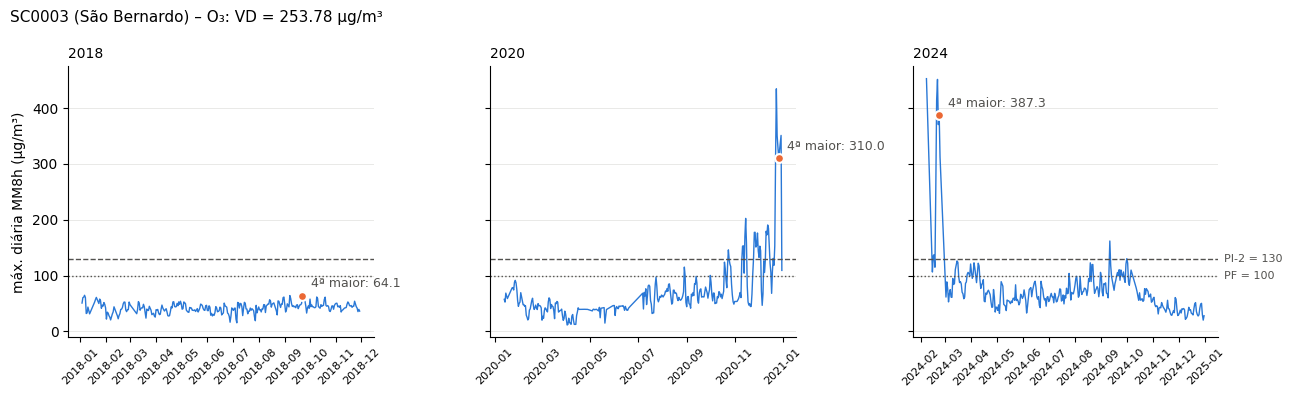

In [31]:
est, pol = 'SC0003', 'O3'
d3 = DIARIO[(est, pol)]
anos = ANOS.set_index(['estacao', 'poluente']).loc[(est, pol), 'anos_selecionados']
vd = VD.set_index(['estacao', 'poluente']).loc[(est, pol), 'VD']

fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, a in zip(axs, anos):
    da = d3[d3.index.year == a]
    ax.plot(da.index, da.values, color='#2a78d6', lw=1)
    q4 = np.sort(da.values)[-4]
    ax.scatter(da.index[da.values == q4], [q4] * (da.values == q4).sum(), s=40, color='#eb6834', zorder=3,
               edgecolor='white', linewidth=1.5)
    ax.annotate(f'4ª maior: {q4:.1f}', (da.index[da.values == q4][0], q4), xytext=(6, 6),
                textcoords='offset points', fontsize=9, color='#52514e')
    for fase, ls in (('PI-2', '--'), ('PF', ':')):
        ax.axhline(PQAR[pol][fase], color='#52514e', lw=1, ls=ls)
        if a == anos[-1]:                       # rótulo à direita do último painel
            ax.annotate(f'{fase} = {PQAR[pol][fase]}', (1, PQAR[pol][fase]), xycoords=('axes fraction', 'data'),
                        xytext=(4, 0), textcoords='offset points', va='center', fontsize=8, color='#52514e')
    ax.set_title(str(a), loc='left', fontsize=10)
    ax.tick_params(axis='x', labelrotation=45, labelsize=8)
    ax.grid(axis='y', color='#e5e5e3', lw=.6)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
axs[0].set_ylabel('máx. diária MM8h (µg/m³)')
fig.suptitle(f'{est} ({NOME[est]}) – O₃: VD = {vd:.2f} µg/m³', x=.01, ha='left', fontsize=11)
plt.tight_layout(); plt.show()

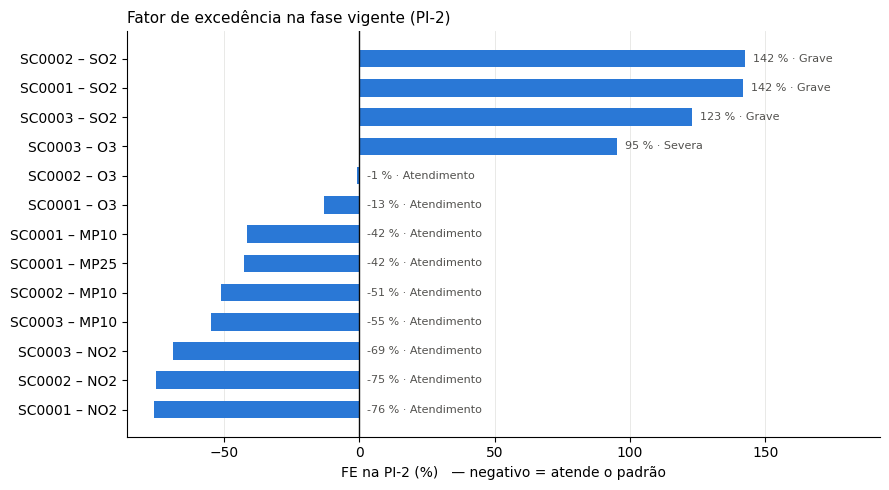

In [32]:
# Fator de excedência na fase vigente (PI-2) para todas as séries com VD
g = VD.dropna(subset=['PI-2_FE_pct']).assign(rot=lambda x: x.estacao + ' – ' + x.poluente)
g = g.sort_values('PI-2_FE_pct')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(g.rot, g['PI-2_FE_pct'], color='#2a78d6', height=.6)
ax.axvline(0, color='#0b0b0b', lw=1)
for y, (v, c) in enumerate(zip(g['PI-2_FE_pct'], g['PI-2_classe'])):
    ax.text(max(v, 0) + 3, y, f'{v:.0f} % · {c}', va='center', ha='left', fontsize=8, color='#52514e')
ax.set_xlabel('FE na PI-2 (%)   — negativo = atende o padrão')
ax.set_title('Fator de excedência na fase vigente (PI-2)', loc='left', fontsize=11)
ax.set_axisbelow(True)
ax.grid(axis='x', color='#e5e5e3', lw=.6)
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
ax.set_xlim(g['PI-2_FE_pct'].min() - 10, g['PI-2_FE_pct'].max() + 50)
plt.tight_layout(); plt.show()

In [33]:
anual_rows = []
for _, r in ANOS.iterrows():
    est, pol, anos = r.estacao, r.poluente, r.anos_selecionados
    if pol not in PQAR_ANUAL or len(anos) < 3:
        continue
    s = SERIES[(est, pol)]
    dm = s.resample('D').mean().where(dias_validos(s))
    dm = dm[dm.index.year.isin(anos)].dropna()
    if pol == 'PTS':
        ma = {a: float(np.exp(np.log(dm[dm.index.year == a].clip(lower=0.01)).mean())) for a in anos}
        metodo = 'média das 3 médias geométricas anuais'
    else:
        ma = {a: float(dm[dm.index.year == a].mean()) for a in anos}
        metodo = 'média das 3 médias aritméticas anuais'
    vda = np.mean(list(ma.values()))
    cl = classificar(vda, pol, PQAR_ANUAL[pol], severidade=False)
    anual_rows.append(dict(estacao=est, poluente=pol, padrao='Anual', anos=' '.join(map(str, anos)), metodo=metodo,
                           VD=vda, **{f'media_{i+1}': v for i, v in enumerate(ma.values())},
                           **{f'{k}_classe': v[0] for k, v in cl.items()}, **{f'{k}_FE_pct': v[1] for k, v in cl.items()}))
    if pol == 'PTS':
        vdp = np.percentile(dm, 98)
        cl = classificar(vdp, pol, PTS24, severidade=False)
        anual_rows.append(dict(estacao=est, poluente=pol, padrao='24 h', anos=' '.join(map(str, anos)),
                               metodo='P98 médias diárias (premissa)', VD=vdp,
                               **{f'{k}_classe': v[0] for k, v in cl.items()}, **{f'{k}_FE_pct': v[1] for k, v in cl.items()}))
ANUAL = pd.DataFrame(anual_rows)
ANUAL.round(2)

,estacao,poluente,padrao,anos,metodo,VD,media_1,media_2,media_3,PI-1_classe,PI-2_classe,PI-3_classe,PI-4_classe,PF_classe,PI-1_FE_pct,PI-2_FE_pct,PI-3_FE_pct,PI-4_FE_pct,PF_FE_pct
0,SC0001,MP10,Anual,2022 2023 2024,média das 3 médias aritméticas anuais,28.61,29.90,27.23,28.71,Atendimento,Atendimento,Atendimento,Não atendimento,Não atendimento,-28.47,-18.25,-4.63,43.06,90.74
1,SC0001,MP25,Anual,2022 2023 2024,média das 3 médias aritméticas anuais,11.84,11.87,10.81,12.86,Atendimento,Atendimento,Atendimento,Não atendimento,Não atendimento,-40.78,-30.32,-21.03,18.45,136.90
2,SC0001,NO2,Anual,2022 2023 2024,média das 3 médias aritméticas anuais,12.38,12.40,12.30,12.44,Atendimento,Atendimento,Atendimento,Atendimento,Não atendimento,-79.36,-75.24,-72.49,-69.05,23.82
3,SC0001,PTS,Anual,2022 2023 2024,média das 3 médias geométricas anuais,35.06,38.62,33.81,32.76,NaN,NaN,NaN,Atendimento,NaN,NaN,NaN,NaN,-56.17,NaN
4,SC0001,PTS,24 h,2022 2023 2024,P98 médias diárias (premissa),75.14,NaN,NaN,NaN,NaN,NaN,NaN,Atendimento,NaN,NaN,NaN,NaN,-68.69,NaN
5,SC0001,SO2,Anual,2020 2021 2024,média das 3 médias aritméticas anuais,20.21,17.50,25.98,17.15,Atendimento,Atendimento,Não atendimento,Não atendimento,Não atendimento,-49.48,-32.63,1.05,1.05,1.05
6,SC0002,MP10,Anual,2022 2023 2024,média das 3 médias aritméticas anuais,22.43,25.71,22.26,19.32,Atendimento,Atendimento,Atendimento,Não atendimento,Não atendimento,-43.92,-35.91,-25.23,12.15,49.54
7,SC0002,NO2,Anual,2019 2020 2021,média das 3 médias aritméticas anuais,10.98,10.69,10.90,11.34,Atendimento,Atendimento,Atendimento,Atendimento,Não atendimento,-81.71,-78.05,-75.61,-72.56,9.76
8,SC0002,PTS,Anual,2022 2023 2024,média das 3 médias geométricas anuais,26.08,32.88,25.89,19.48,NaN,NaN,NaN,Atendimento,NaN,NaN,NaN,NaN,-67.40,NaN
9,SC0002,PTS,24 h,2022 2023 2024,P98 médias diárias (premissa),61.83,NaN,NaN,NaN,NaN,NaN,NaN,Atendimento,NaN,NaN,NaN,NaN,-74.24,NaN


In [34]:
sens = []
for _, r in ANOS[ANOS.poluente == 'O3'].iterrows():
    est, anos = r.estacao, r.anos_selecionados
    s = SERIES[(est, 'O3')]
    d3 = DIARIO[(est, 'O3')]
    noturna = s[s.index.hour <= 5].resample('D').mean()
    suspeitos = noturna[noturna > 100].index
    d3s = d3.drop(d3.index.intersection(suspeitos))
    vd_todos = np.mean([np.sort(d3[d3.index.year == a].values)[-4] for a in anos])
    vd_sem = np.mean([np.sort(d3s[d3s.index.year == a].values)[-4] for a in anos])
    sens.append(dict(estacao=est, VD_O3_todos_dados=vd_todos, VD_O3_sem_dias_suspeitos=vd_sem,
                     dias_suspeitos_excluidos=int(suspeitos.year.isin(anos).sum())))  # dias suspeitos nos 3 anos (válidos ou não)
SENS = pd.DataFrame(sens)
SENS.round(1)

,estacao,VD_O3_todos_dados,VD_O3_sem_dias_suspeitos,dias_suspeitos_excluidos
0,SC0001,113.3,84.9,4
1,SC0002,129.0,118.7,15
2,SC0003,253.8,119.2,28


In [35]:
def confere(nome, novo, ref, chaves, colunas, tol=0.06):
    m = novo.merge(ref, on=chaves, suffixes=('', '_ref'))
    erros = sum(int((~np.isclose(m[c], m[f'{c}_ref'], atol=tol, equal_nan=True)).sum()) for c in colunas)
    print(f'{nome:<32} linhas comparadas: {len(m):>3}   diferenças: {erros}')
    return erros

ref_rep = pd.read_csv(REF / '02_representatividade_anual.csv').rename(columns={'estacao': 'estacao', 'poluente': 'poluente'})
ref_vd = pd.read_csv(REF / '05_vd_classificacao_curto_prazo.csv').rename(columns={'VD_ug_m3_ou_ppm': 'VD'})
ref_det = pd.read_csv(REF / '07_vd_detalhe_anual.csv')
ref_sens = pd.read_csv(REF / '09_sensibilidade_O3.csv')

total = 0
total += confere('Representatividade anual', REP, ref_rep, ['estacao', 'poluente', 'ano'],
                 ['pct_horas_validas', 'pct_dias_validos', 'meses_validos',
                  'pct_dias_validos_Q1_jan_abr', 'pct_dias_validos_Q2_mai_ago', 'pct_dias_validos_Q3_set_dez'])
total += confere('VD e FE (curto prazo)', VD, ref_vd, ['estacao', 'poluente'],
                 ['VD', 'n_dias_validos'] + [f'{f}_FE_pct' for f in FASES])
classes_ok = (VD.merge(ref_vd, on=['estacao', 'poluente'], suffixes=('', '_ref'))
                .pipe(lambda m: all((m[f'{f}_classe'] == m[f'{f}_classe_ref']).all() for f in FASES)))
print(f'{"Classes de severidade":<32} iguais: {classes_ok}')
total += confere('Detalhe anual', DETALHE, ref_det, ['estacao', 'poluente', 'ano'],
                 ['dias_validos', 'max_estatistica_diaria', 'P98_ano', 'P99_ano', 'quarta_maior_MM8h_O3'])
total += confere('Sensibilidade O3', SENS, ref_sens, ['estacao'],
                 ['VD_O3_todos_dados', 'VD_O3_sem_dias_suspeitos', 'dias_suspeitos_excluidos'])
print('\nOK com relatório' if total == 0 and classes_ok else '\nATENÇÃO: há diferenças')

Representatividade anual         linhas comparadas: 178   diferenças: 0
VD e FE (curto prazo)            linhas comparadas:  13   diferenças: 0
Classes de severidade            iguais: True
Detalhe anual                    linhas comparadas:  39   diferenças: 0
Sensibilidade O3                 linhas comparadas:   3   diferenças: 0

OK: tudo igual ao relatório


In [36]:
import openpyxl
xlsx = BASE / 'MediaMovel_Preenchido.xlsx'
if xlsx.exists():
    ws = openpyxl.load_workbook(xlsx, read_only=True, data_only=True)['Enquadramento']
    lin = list(ws.iter_rows(min_row=4, max_row=9, min_col=23, max_col=24, values_only=True))  # W4:X9
    cel = {'X4': lin[0][1], 'X5': lin[1][1], 'X6': lin[2][1], 'W9': lin[5][0]}
    q4_nb = DETALHE.query("estacao == 'SC0003' and poluente == 'O3'").set_index('ano')['quarta_maior_MM8h_O3']
    vd_nb = VD.query("estacao == 'SC0003' and poluente == 'O3'")['VD'].iloc[0]
    comp = pd.DataFrame({'planilha': [cel['X4'], cel['X5'], cel['X6'], cel['W9']],
                         'notebook': [*q4_nb.values, vd_nb]},
                        index=[f'4ª maior {a}' for a in q4_nb.index] + ['VD'])
    comp['igual'] = np.isclose(comp.planilha.astype(float), comp.notebook)
    display(comp.round(2))
else:
    print('Planilha não encontrada:', xlsx.name, '(conferência opcional)')

Planilha não encontrada: MediaMovel_Preenchido.xlsx (conferência opcional)


In [37]:
with pd.ExcelWriter(OUT / 'resultados_atividade02.xlsx') as xw:
    REP.round(2).to_excel(xw, sheet_name='Representatividade', index=False)
    MENSAL.round(1).pivot_table(index=['estacao', 'poluente', 'ano'], columns='mes',
                                values='pct_dias_validos').to_excel(xw, sheet_name='Mensal_pct_dias')
    ANOS.assign(anos_selecionados=ANOS.anos_selecionados.map(lambda a: ' '.join(map(str, a))),
                todos_anos_representativos=ANOS.todos_anos_representativos.map(lambda a: ' '.join(map(str, a)))
                ).to_excel(xw, sheet_name='Anos_selecionados', index=False)
    VD.round(2).to_excel(xw, sheet_name='VD_curto_prazo', index=False)
    DETALHE.round(2).to_excel(xw, sheet_name='Detalhe_anual', index=False)
    ANUAL.round(2).to_excel(xw, sheet_name='Anuais_PTS', index=False)
    SENS.round(2).to_excel(xw, sheet_name='Sensibilidade_O3', index=False)
print('Salvo em', (OUT / 'resultados_atividade02.xlsx').relative_to(BASE))

Salvo em saida_notebook/resultados_atividade02.xlsx
